> **Atribución.** Esta libreta es material del curso de Aprendizaje Profundo (UAM), adaptado al español a partir de los tutoriales de [Naoki Shibuya](https://github.com/naokishibuya/deep-learning) y de los ejemplos de Udacity citados en la sección de referencias. No es un trabajo original mío: mi aporte es la ejecución, la experimentación con hiperparámetros.

# Generador Adversario Convolucional Profundo (DCGAN) con MNIST

Utiliza redes convolucionales profundas en el generador y el discriminador.

In [ ]:
import numpy as np
from scipy.io import loadmat
import keras
import keras.backend as K
from keras.layers import Dense, Activation, LeakyReLU, BatchNormalization
from keras.layers import Conv2D, Conv2DTranspose, Reshape, Flatten
from keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.8.0


In [ ]:
!pip install tensorflow==2.8.0
import tensorflow as tf
print(tf.__version__)

2.8.0


## Cargando el Conjunto de Datos MNIST



In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

11501568/11490434 [==============================] - 0s 0us/step


Solo utilizamos las imágenes, no las etiquetas categóricas.

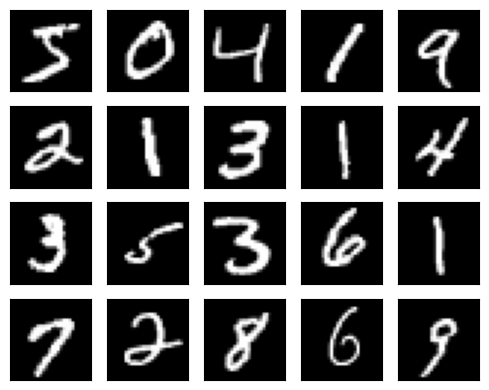

In [ ]:
plt.figure(figsize=(5, 4))
for i in range(20):
    plt.subplot(4, 5, i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

## Preprocesamiento y Desprocesamiento

Como es habitual, necesitamos realizar un preprocesamiento y posterior desprocesamiento de las imágenes.

Como veremos más adelante, el generador utiliza una activación `tanh`, por lo que debemos preprocesar los datos de la imagen para que estén en el rango entre -1 y 1.

In [ ]:
def preprocess(x):
    x = x.reshape(-1, 28, 28, 1) # 28,28,1
    x = np.float64(x)
    x = (x / 255 - 0.5) * 2
    x = np.clip(x, -1, 1)
    return x

def deprocess(x):
    x = (x / 2 + 1) * 255
    x = np.clip(x, 0, 255)
    x = np.uint8(x)
    x = x.reshape(28, 28)
    return x

Aplica el preprocesamiento a las imágenes de entrenamiento y prueba (que son las imágenes reales en contraposición a las imágenes generadas).

In [ ]:
X_train_real = preprocess(X_train)
X_test_real  = preprocess(X_test)

## Generador

El artículo original de DCGAN [[3]](#ref3) propone la siguiente arquitectura de red generadora.

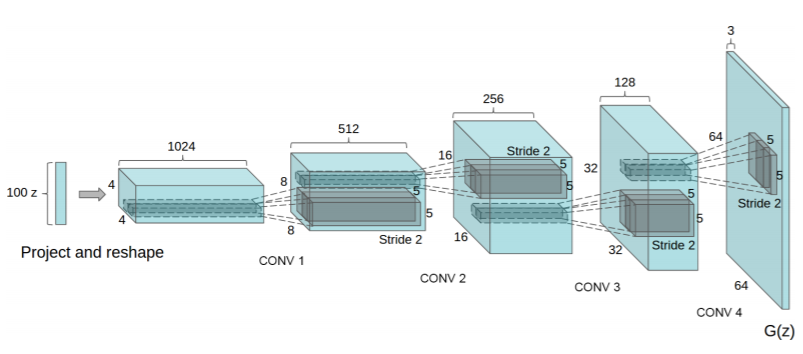

En este cuaderno, utilicé redes más pequeñas que las que propone el artículo original [[3]](#ref3) debido a que el tamaño de nuestra imagen es de 28x28 y solo tiene 1 canal.

El generador toma una muestra latente de 100 números aleatorios y genera una imagen de 28x28 con 1 canal.

La primera capa acepta 784 puntos de datos. Luego, reconfigura los datos a una forma de 7x7 con 16 filtros. Después, dos capas de convolución transpuesta aumentarán el tamaño de los datos a 28x28.


In [ ]:
def make_generator(input_size, leaky_alpha):
    # generates images in (28,28,1)
    return Sequential([
        # FC 1: 7,7,16
        Dense(784, input_shape=(input_size,)),
        Reshape(target_shape=(7, 7, 16)),
        BatchNormalization(),
        LeakyReLU(alpha=leaky_alpha),

        # Conv 1: 14,14,32
        Conv2DTranspose(32, kernel_size=5, strides=2, padding='same'),
        BatchNormalization(),
        LeakyReLU(alpha=leaky_alpha),

        # Conv 2: 28,28,1
        Conv2DTranspose(1, kernel_size=5, strides=2, padding='same'),
        Activation('tanh')
    ])

## Discriminador


El discriminador es un clasificador que determina si la imagen de entrada es real o falsa.

Es una red neuronal convolucional que toma una imagen de 28x28 con 1 canal. Se espera que los valores en la imagen estén en el rango entre -1 y 1.

La activación de la capa de salida es `sigmoid`, y el discriminador produce una probabilidad de que la imagen sea real.

Utilicé una capa completamente conectada con 784 (=28x28) neuronas. Para que este discriminador sea comparable, he utilizado el mismo número de neuronas en la última capa oculta completamente conectada y luego añadí capas de convolución antes de esta capa.

Nota: el uso de un número decreciente de filtros puede ser un poco inusual, pero lo hice para que la red del discriminador y la red del generador tengan un aumento similar en el número de neuronas de la red convolucional (con suerte, manteniendo un equilibrio en su capacidad).

In [ ]:
def make_discriminator(leaky_alpha):
    # classifies images in (28,28,1)
    return Sequential([
        # Conv 1: 14,14,32
        Conv2D(32, kernel_size=5, strides=2, padding='same', input_shape=(28,28,1)),
        LeakyReLU(alpha=leaky_alpha),

        # Conv 2: 7,7,16
        Conv2D(16, kernel_size=5, strides=2, padding='same'),
        BatchNormalization(),
        LeakyReLU(alpha=leaky_alpha),

        # FC 1
        Flatten(),
        Dense(784),
        BatchNormalization(),
        LeakyReLU(alpha=leaky_alpha),

        # Output
        Dense(1),
        Activation('sigmoid')
    ])

### Acerca de la Normalización por Lotes (Batch Normalization)

En cuanto a la normalización por lotes (batch normalization), esta se aplicó a la mayoría de las capas, pero no a todas. La siguiente cita proviene del artículo original de DCGAN [[3]](#ref3):

> Aplicar directamente la normalización por lotes a todas las capas resultó en oscilación de las muestras e inestabilidad del modelo. Esto se evitó al no aplicar la normalización por lotes a la capa de salida del generador y a la capa de entrada del discriminador.

## DCGAN

Conectamos el generador y el discriminador para crear un DCGAN.

La entrada al DCGAN es una muestra latente. El generador dentro del DCGAN produce una imagen que se alimenta al discriminador dentro del DCGAN. Por lo tanto, la salida del DCGAN es la probabilidad de que la imagen generada sea real.

In [ ]:
# beta_1 is the exponential decay rate for the 1st moment estimates in Adam optimizer
def make_DCGAN(sample_size, g_learning_rate, g_beta_1, d_learning_rate, d_beta_1, leaky_alpha):
    # clear first
    K.clear_session()

    # generator
    generator = make_generator(sample_size, leaky_alpha)

    # discriminator
    discriminator = make_discriminator(leaky_alpha)
    discriminator.compile(optimizer=Adam(learning_rate=d_learning_rate, beta_1=d_beta_1), loss='binary_crossentropy')

    # GAN
    gan = Sequential([generator, discriminator])
    gan.compile(optimizer=Adam(learning_rate=g_learning_rate, beta_1=g_beta_1), loss='binary_crossentropy')

    return gan, generator, discriminator

## Entrenamiento de DCGAN

A continuación, se presenta una función para generar muestras latentes.

In [ ]:
def make_latent_samples(n_samples, sample_size):
    #return np.random.uniform(-1, 1, size=(n_samples, sample_size))
    return np.random.normal(loc=0, scale=1, size=(n_samples, sample_size))

La siguiente es una función para establecer el discriminador como entrenable o no entrenable.

In [ ]:
def make_trainable(model, trainable):
    for layer in model.layers:
        layer.trainable = trainable

La siguiente es una función para crear un lote de etiquetas.

In [ ]:
def make_labels(size):
    return np.ones([size, 1]), np.zeros([size, 1])

Lo siguiente es para mostrar las pérdidas.

In [ ]:
def show_results(losses):
    labels = ['Classifier', 'Discriminator', 'Generator']
    losses = np.array(losses)

    fig, ax = plt.subplots()
    plt.plot(losses.T[0], label='Discriminator')
    plt.plot(losses.T[1], label='Generator')
    plt.title("Training Losses")
    plt.legend()
    plt.show()

Lo siguiente es para mostrar las imágenes generadas.

In [ ]:
def show_images(generated_images):
    n_images = len(generated_images)
    rows = 4
    cols = n_images//rows

    plt.figure(figsize=(cols, rows))
    for i in range(n_images):
        img = deprocess(generated_images[i])
        plt.subplot(rows, cols, i+1)
        plt.imshow(img, cmap='gray')
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()

El entrenamiento de DCGAN es esencialmente el mismo que el entrenamiento de una GAN simple:

1. Establecer el discriminador como entrenable.
2. Entrenar el discriminador con imágenes reales con suavizado de etiquetas (etiquetas=1-suavizado).
3. Entrenar el discriminador con imágenes falsas generadas por el generador (etiquetas=0).
4. Establecer el discriminador como no entrenable.
5. Entrenar el DCGAN con imágenes generadas (etiquetas=1).

Repetimos este proceso muchas veces hasta que la pérdida del discriminador y la pérdida del generador se estabilicen.

In [ ]:
def train(
    g_learning_rate,   # learning rate for the generator
    g_beta_1,          # the exponential decay rate for the 1st moment estimates in Adam optimizer
    d_learning_rate,   # learning rate for the discriminator
    d_beta_1,          # the exponential decay rate for the 1st moment estimates in Adam optimizer
    leaky_alpha,
    smooth=0.1,        # label smoothing
    sample_size=100,   # latent sample size (i.e. 100 random numbers)
    epochs=100,
    batch_size=128,    # train batch size
    eval_size=16,      # evaluate size
    show_details=True):

    # labels for the batch size and the test size
    y_train_real, y_train_fake = make_labels(batch_size)
    y_eval_real,  y_eval_fake  = make_labels(eval_size)

    # create a GAN, a generator and a discriminator
    gan, generator, discriminator = make_DCGAN(sample_size, g_learning_rate, g_beta_1, d_learning_rate, d_beta_1, leaky_alpha)

    losses = []
    for e in range(epochs):
        for i in range(len(X_train_real)//batch_size):
            # real MNIST digit images
            X_batch_real = X_train_real[i*batch_size:(i+1)*batch_size]

            # latent samples and the generated digit images
            latent_samples = make_latent_samples(batch_size, sample_size)
            X_batch_fake = generator.predict_on_batch(latent_samples)

            # train the discriminator to detect real and fake images
            make_trainable(discriminator, True)
            discriminator.train_on_batch(X_batch_real, y_train_real * (1 - smooth))
            discriminator.train_on_batch(X_batch_fake, y_train_fake)

            # train the generator via GAN
            make_trainable(discriminator, False)
            gan.train_on_batch(latent_samples, y_train_real)

        # evaluate
        X_eval_real = X_test_real[np.random.choice(len(X_test_real), eval_size, replace=False)]

        latent_samples = make_latent_samples(eval_size, sample_size)
        X_eval_fake = generator.predict_on_batch(latent_samples)

        d_loss  = discriminator.test_on_batch(X_eval_real, y_eval_real)
        d_loss += discriminator.test_on_batch(X_eval_fake, y_eval_fake)
        g_loss  = gan.test_on_batch(latent_samples, y_eval_real) # we want the fake to be realistic!

        losses.append((d_loss, g_loss))

        print("Epoch:{:>3}/{} Discriminator Loss:{:>7.4f} Generator Loss:{:>7.4f}".format(
            e+1, epochs, d_loss, g_loss))

        if show_details and (e+1)%10==0:
            show_images(X_eval_fake)
    if show_details:
        show_results(losses)
    return generator

Epoch:  1/100 Discriminator Loss: 6.0245 Generator Loss: 0.0150
Epoch:  2/100 Discriminator Loss: 5.8994 Generator Loss: 0.0028
Epoch:  3/100 Discriminator Loss:166.0930 Generator Loss:53.8277
Epoch:  4/100 Discriminator Loss:80.7594 Generator Loss:38.6498
Epoch:  5/100 Discriminator Loss:18.8237 Generator Loss: 3.8912
Epoch:  6/100 Discriminator Loss:35.1365 Generator Loss:10.0947
Epoch:  7/100 Discriminator Loss:17.5295 Generator Loss: 9.3137
Epoch:  8/100 Discriminator Loss: 3.1896 Generator Loss:15.3132
Epoch:  9/100 Discriminator Loss: 8.1455 Generator Loss: 5.5577
Epoch: 10/100 Discriminator Loss: 5.3687 Generator Loss: 3.0520


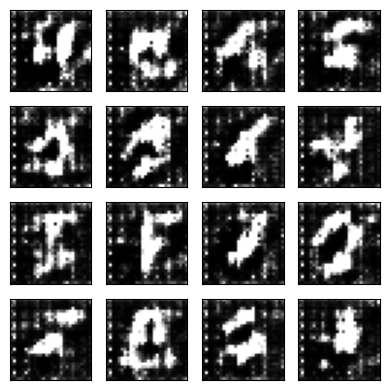

Epoch: 11/100 Discriminator Loss: 4.3702 Generator Loss: 3.7589
Epoch: 12/100 Discriminator Loss: 2.5007 Generator Loss: 2.5461
Epoch: 13/100 Discriminator Loss: 4.0369 Generator Loss: 4.0453
Epoch: 14/100 Discriminator Loss: 7.5219 Generator Loss: 4.9011
Epoch: 15/100 Discriminator Loss: 3.5019 Generator Loss: 2.7011
Epoch: 16/100 Discriminator Loss: 2.0496 Generator Loss: 0.3252
Epoch: 17/100 Discriminator Loss:10.9963 Generator Loss: 9.7168
Epoch: 18/100 Discriminator Loss:22.5281 Generator Loss:21.4904
Epoch: 19/100 Discriminator Loss: 3.7792 Generator Loss: 4.0859
Epoch: 20/100 Discriminator Loss: 5.2788 Generator Loss: 6.7598


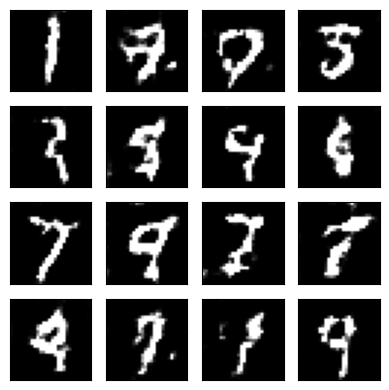

Epoch: 21/100 Discriminator Loss: 3.0185 Generator Loss: 3.1394
Epoch: 22/100 Discriminator Loss: 2.2342 Generator Loss: 1.4676
Epoch: 23/100 Discriminator Loss: 3.3208 Generator Loss: 2.7287
Epoch: 24/100 Discriminator Loss: 5.9472 Generator Loss: 6.0325
Epoch: 25/100 Discriminator Loss: 7.9603 Generator Loss: 7.3623
Epoch: 26/100 Discriminator Loss: 3.6784 Generator Loss: 3.8863
Epoch: 27/100 Discriminator Loss: 6.6354 Generator Loss: 5.7499
Epoch: 28/100 Discriminator Loss: 2.2190 Generator Loss: 2.1509
Epoch: 29/100 Discriminator Loss: 2.4079 Generator Loss: 2.5954
Epoch: 30/100 Discriminator Loss: 3.9630 Generator Loss: 4.5336


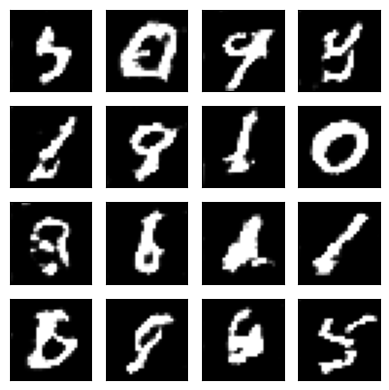

Epoch: 31/100 Discriminator Loss: 2.0718 Generator Loss: 3.0639
Epoch: 32/100 Discriminator Loss: 1.2748 Generator Loss: 1.7759
Epoch: 33/100 Discriminator Loss: 2.2543 Generator Loss: 0.4558
Epoch: 34/100 Discriminator Loss: 4.0267 Generator Loss: 5.3462
Epoch: 35/100 Discriminator Loss: 1.3837 Generator Loss: 1.8209
Epoch: 36/100 Discriminator Loss: 2.1241 Generator Loss: 3.4685
Epoch: 37/100 Discriminator Loss: 2.2045 Generator Loss: 3.2524
Epoch: 38/100 Discriminator Loss: 6.9639 Generator Loss: 6.2388
Epoch: 39/100 Discriminator Loss: 1.1815 Generator Loss: 1.4034
Epoch: 40/100 Discriminator Loss: 1.9450 Generator Loss: 2.8530


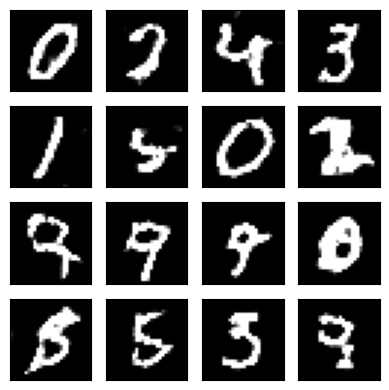

Epoch: 41/100 Discriminator Loss: 2.2784 Generator Loss: 4.5442
Epoch: 42/100 Discriminator Loss: 1.3057 Generator Loss: 1.6051
Epoch: 43/100 Discriminator Loss: 5.4286 Generator Loss: 5.3921
Epoch: 44/100 Discriminator Loss: 2.8043 Generator Loss: 4.1742
Epoch: 45/100 Discriminator Loss: 2.0024 Generator Loss: 0.6875
Epoch: 46/100 Discriminator Loss: 2.0834 Generator Loss: 2.8221
Epoch: 47/100 Discriminator Loss: 2.6396 Generator Loss: 2.7151
Epoch: 48/100 Discriminator Loss: 9.0412 Generator Loss: 6.1663
Epoch: 49/100 Discriminator Loss: 1.6515 Generator Loss: 2.3260
Epoch: 50/100 Discriminator Loss: 1.1832 Generator Loss: 1.4918


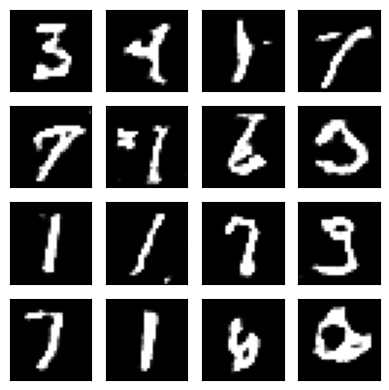

Epoch: 51/100 Discriminator Loss: 3.7950 Generator Loss: 4.4961
Epoch: 52/100 Discriminator Loss: 2.5028 Generator Loss: 3.3791
Epoch: 53/100 Discriminator Loss: 1.6541 Generator Loss: 2.7218
Epoch: 54/100 Discriminator Loss: 1.6430 Generator Loss: 1.9182
Epoch: 55/100 Discriminator Loss: 5.7683 Generator Loss: 6.4929
Epoch: 56/100 Discriminator Loss: 1.5572 Generator Loss: 1.4375
Epoch: 57/100 Discriminator Loss: 2.9049 Generator Loss: 3.8050
Epoch: 58/100 Discriminator Loss: 1.6229 Generator Loss: 2.3032
Epoch: 59/100 Discriminator Loss: 1.8250 Generator Loss: 3.1318
Epoch: 60/100 Discriminator Loss: 1.4334 Generator Loss: 2.2110


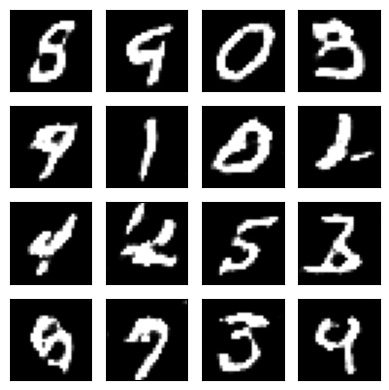

Epoch: 61/100 Discriminator Loss: 2.4089 Generator Loss: 3.2949
Epoch: 62/100 Discriminator Loss: 4.5676 Generator Loss: 3.9219
Epoch: 63/100 Discriminator Loss: 3.2208 Generator Loss: 3.6867
Epoch: 64/100 Discriminator Loss: 1.6450 Generator Loss: 3.4375
Epoch: 65/100 Discriminator Loss: 6.9836 Generator Loss: 6.6653
Epoch: 66/100 Discriminator Loss: 1.2477 Generator Loss: 1.5188
Epoch: 67/100 Discriminator Loss: 9.7503 Generator Loss: 9.8932
Epoch: 68/100 Discriminator Loss: 1.5225 Generator Loss: 1.4372
Epoch: 69/100 Discriminator Loss: 1.0932 Generator Loss: 1.1991
Epoch: 70/100 Discriminator Loss: 1.2764 Generator Loss: 2.3969


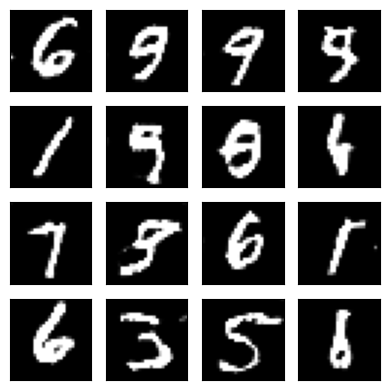

Epoch: 71/100 Discriminator Loss: 2.5630 Generator Loss: 3.5844
Epoch: 72/100 Discriminator Loss: 3.4280 Generator Loss: 4.5416
Epoch: 73/100 Discriminator Loss: 1.3558 Generator Loss: 2.4317
Epoch: 74/100 Discriminator Loss: 2.7266 Generator Loss: 2.3654
Epoch: 75/100 Discriminator Loss: 2.1950 Generator Loss: 2.1812
Epoch: 76/100 Discriminator Loss: 1.0683 Generator Loss: 1.1496
Epoch: 77/100 Discriminator Loss: 4.0492 Generator Loss: 4.1347
Epoch: 78/100 Discriminator Loss: 5.7053 Generator Loss: 6.1084
Epoch: 79/100 Discriminator Loss: 5.2612 Generator Loss: 4.2909
Epoch: 80/100 Discriminator Loss: 1.9889 Generator Loss: 2.8078


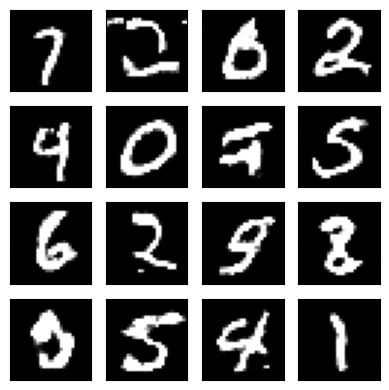

Epoch: 81/100 Discriminator Loss: 5.2193 Generator Loss: 4.3263
Epoch: 82/100 Discriminator Loss: 2.7628 Generator Loss: 4.2326
Epoch: 83/100 Discriminator Loss: 1.4679 Generator Loss: 1.9053
Epoch: 84/100 Discriminator Loss: 1.8801 Generator Loss: 2.8584
Epoch: 85/100 Discriminator Loss: 3.3538 Generator Loss: 4.5787
Epoch: 86/100 Discriminator Loss: 3.1116 Generator Loss: 4.2013
Epoch: 87/100 Discriminator Loss: 1.1668 Generator Loss: 2.2930
Epoch: 88/100 Discriminator Loss: 4.2859 Generator Loss: 3.5321
Epoch: 89/100 Discriminator Loss:12.4606 Generator Loss:12.6763
Epoch: 90/100 Discriminator Loss: 1.0992 Generator Loss: 1.2644


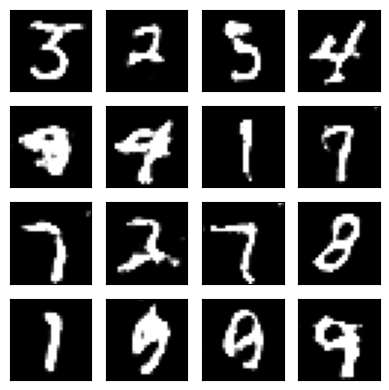

Epoch: 91/100 Discriminator Loss: 2.1324 Generator Loss: 2.5897
Epoch: 92/100 Discriminator Loss: 2.3155 Generator Loss: 3.5479
Epoch: 93/100 Discriminator Loss: 2.8151 Generator Loss: 3.5713
Epoch: 94/100 Discriminator Loss: 3.6513 Generator Loss: 4.1772


In [ ]:
train(g_learning_rate=0.0001, g_beta_1=0.9, d_learning_rate=0.001, d_beta_1=0.9, leaky_alpha=0.01);

Sin duda, es mucho mejor que los resultados del modelo simple de GAN para MNIST.

Epoch:  1/100 Discriminator Loss: 3.6239 Generator Loss: 0.2761
Epoch:  2/100 Discriminator Loss: 5.5753 Generator Loss: 0.6399
Epoch:  3/100 Discriminator Loss: 0.4141 Generator Loss: 1.4790
Epoch:  4/100 Discriminator Loss: 3.9921 Generator Loss: 4.1315
Epoch:  5/100 Discriminator Loss: 7.2302 Generator Loss: 9.7049
Epoch:  6/100 Discriminator Loss: 1.0647 Generator Loss: 1.6362
Epoch:  7/100 Discriminator Loss: 2.1817 Generator Loss: 3.5970
Epoch:  8/100 Discriminator Loss: 1.5998 Generator Loss: 2.2137
Epoch:  9/100 Discriminator Loss: 6.2936 Generator Loss: 7.5784
Epoch: 10/100 Discriminator Loss: 2.0222 Generator Loss: 4.0872


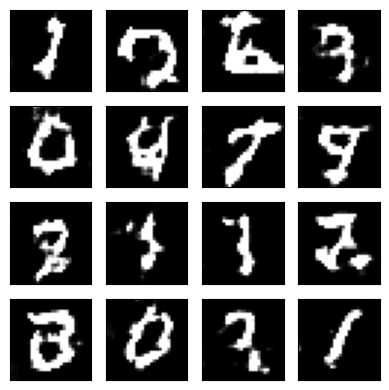

Epoch: 11/100 Discriminator Loss: 7.1694 Generator Loss: 8.9136
Epoch: 12/100 Discriminator Loss: 9.0245 Generator Loss:10.6249
Epoch: 13/100 Discriminator Loss: 2.3577 Generator Loss: 4.0692
Epoch: 14/100 Discriminator Loss: 6.0133 Generator Loss: 6.6669
Epoch: 15/100 Discriminator Loss: 1.6158 Generator Loss: 3.3526
Epoch: 16/100 Discriminator Loss: 1.7412 Generator Loss: 1.9829
Epoch: 17/100 Discriminator Loss: 1.6341 Generator Loss: 1.2926
Epoch: 18/100 Discriminator Loss: 2.0602 Generator Loss: 1.4669
Epoch: 19/100 Discriminator Loss: 2.6797 Generator Loss: 0.6819
Epoch: 20/100 Discriminator Loss: 3.2231 Generator Loss: 1.7248


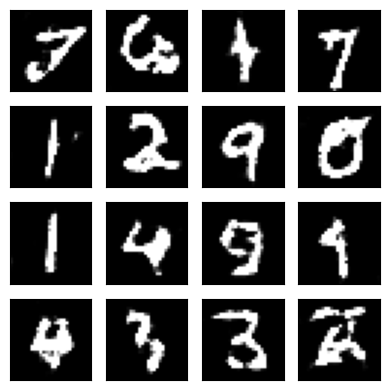

Epoch: 21/100 Discriminator Loss: 2.8028 Generator Loss: 3.1571
Epoch: 22/100 Discriminator Loss: 3.0248 Generator Loss: 1.9056
Epoch: 23/100 Discriminator Loss: 4.2348 Generator Loss: 0.0901
Epoch: 24/100 Discriminator Loss: 4.0133 Generator Loss: 1.1690
Epoch: 25/100 Discriminator Loss: 3.1051 Generator Loss: 0.5468
Epoch: 26/100 Discriminator Loss: 4.9787 Generator Loss: 3.3732
Epoch: 27/100 Discriminator Loss: 2.2044 Generator Loss: 1.4195
Epoch: 28/100 Discriminator Loss: 2.4441 Generator Loss: 0.3741
Epoch: 29/100 Discriminator Loss: 3.9103 Generator Loss: 3.2457
Epoch: 30/100 Discriminator Loss: 5.5516 Generator Loss: 0.2225


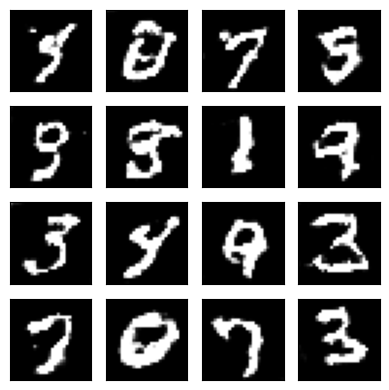

Epoch: 31/100 Discriminator Loss: 2.6452 Generator Loss: 1.8282
Epoch: 32/100 Discriminator Loss: 4.2856 Generator Loss: 0.0798
Epoch: 33/100 Discriminator Loss: 5.6378 Generator Loss: 0.2540
Epoch: 34/100 Discriminator Loss: 2.6560 Generator Loss: 0.3725
Epoch: 35/100 Discriminator Loss: 3.6053 Generator Loss: 3.8822
Epoch: 36/100 Discriminator Loss: 0.9117 Generator Loss: 1.3382
Epoch: 37/100 Discriminator Loss: 2.0707 Generator Loss: 2.1989
Epoch: 38/100 Discriminator Loss: 3.8129 Generator Loss: 2.7294
Epoch: 39/100 Discriminator Loss: 1.8743 Generator Loss: 2.3608
Epoch: 40/100 Discriminator Loss: 2.9734 Generator Loss: 0.1519


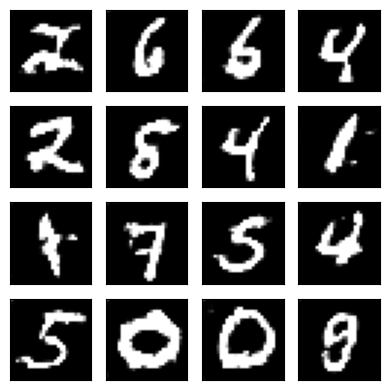

Epoch: 41/100 Discriminator Loss: 1.9743 Generator Loss: 0.8068
Epoch: 42/100 Discriminator Loss: 2.1339 Generator Loss: 0.8331
Epoch: 43/100 Discriminator Loss: 4.0571 Generator Loss: 0.1769
Epoch: 44/100 Discriminator Loss: 1.3167 Generator Loss: 1.7914
Epoch: 45/100 Discriminator Loss: 1.6492 Generator Loss: 1.4966
Epoch: 46/100 Discriminator Loss: 2.6388 Generator Loss: 0.5470
Epoch: 47/100 Discriminator Loss: 2.8378 Generator Loss: 0.4833
Epoch: 48/100 Discriminator Loss: 2.5260 Generator Loss: 0.5393
Epoch: 49/100 Discriminator Loss: 8.4977 Generator Loss: 8.2059
Epoch: 50/100 Discriminator Loss: 4.1669 Generator Loss: 0.3102


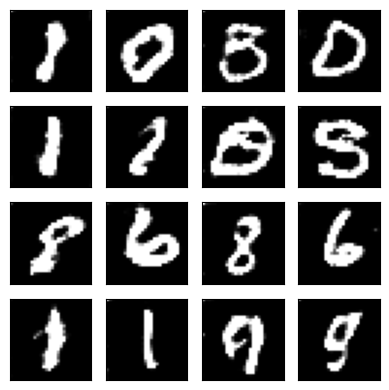

Epoch: 51/100 Discriminator Loss:11.6696 Generator Loss:11.2587
Epoch: 52/100 Discriminator Loss: 3.1633 Generator Loss: 4.4962
Epoch: 53/100 Discriminator Loss: 2.4033 Generator Loss: 2.0883
Epoch: 54/100 Discriminator Loss: 1.4869 Generator Loss: 0.7076
Epoch: 55/100 Discriminator Loss: 6.7291 Generator Loss: 0.0139
Epoch: 56/100 Discriminator Loss: 2.0143 Generator Loss: 1.1967
Epoch: 57/100 Discriminator Loss: 2.2886 Generator Loss: 1.6881
Epoch: 58/100 Discriminator Loss: 0.9418 Generator Loss: 2.5224
Epoch: 59/100 Discriminator Loss: 5.5674 Generator Loss: 7.4934
Epoch: 60/100 Discriminator Loss: 3.0786 Generator Loss: 0.2279


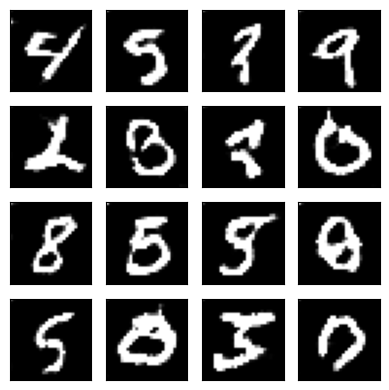

Epoch: 61/100 Discriminator Loss: 1.9935 Generator Loss: 1.5550
Epoch: 62/100 Discriminator Loss: 1.8627 Generator Loss: 1.7633
Epoch: 63/100 Discriminator Loss: 0.9481 Generator Loss: 1.1301
Epoch: 64/100 Discriminator Loss: 1.7333 Generator Loss: 2.5531
Epoch: 65/100 Discriminator Loss: 3.9006 Generator Loss: 0.0610
Epoch: 66/100 Discriminator Loss: 2.1073 Generator Loss: 3.9438
Epoch: 67/100 Discriminator Loss: 1.4893 Generator Loss: 0.9267
Epoch: 68/100 Discriminator Loss: 1.5099 Generator Loss: 0.7459
Epoch: 69/100 Discriminator Loss: 4.5606 Generator Loss: 6.1917
Epoch: 70/100 Discriminator Loss: 1.1260 Generator Loss: 2.2928


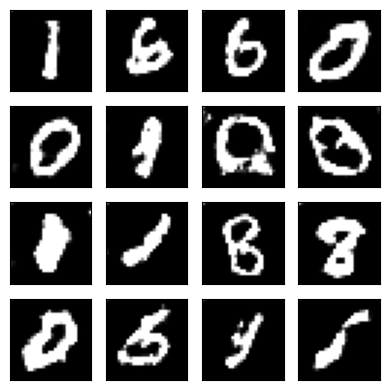

Epoch: 71/100 Discriminator Loss: 2.1367 Generator Loss: 0.3886
Epoch: 72/100 Discriminator Loss: 2.4429 Generator Loss: 2.1682
Epoch: 73/100 Discriminator Loss: 3.4705 Generator Loss: 2.5838
Epoch: 74/100 Discriminator Loss: 3.5830 Generator Loss: 5.6197
Epoch: 75/100 Discriminator Loss: 1.8803 Generator Loss: 2.5926
Epoch: 76/100 Discriminator Loss: 3.4041 Generator Loss: 4.7406
Epoch: 77/100 Discriminator Loss:12.3929 Generator Loss:11.6415
Epoch: 78/100 Discriminator Loss: 3.1029 Generator Loss: 4.9510
Epoch: 79/100 Discriminator Loss: 2.3660 Generator Loss: 3.1573
Epoch: 80/100 Discriminator Loss: 2.5152 Generator Loss: 2.7817


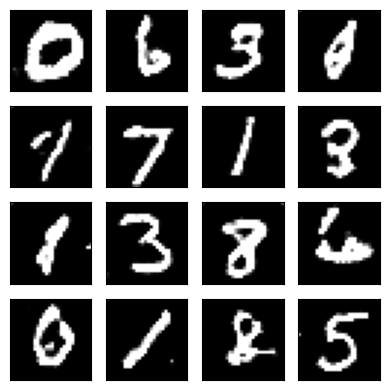

Epoch: 81/100 Discriminator Loss: 3.3468 Generator Loss: 0.3158
Epoch: 82/100 Discriminator Loss: 1.5579 Generator Loss: 1.4388
Epoch: 83/100 Discriminator Loss: 5.8984 Generator Loss: 9.1311
Epoch: 84/100 Discriminator Loss: 1.5787 Generator Loss: 2.1554
Epoch: 85/100 Discriminator Loss: 2.9130 Generator Loss: 1.0331
Epoch: 86/100 Discriminator Loss: 1.0465 Generator Loss: 2.5382
Epoch: 87/100 Discriminator Loss: 2.0990 Generator Loss: 0.3739
Epoch: 88/100 Discriminator Loss: 7.0459 Generator Loss: 7.5808
Epoch: 89/100 Discriminator Loss: 7.3253 Generator Loss: 7.3426
Epoch: 90/100 Discriminator Loss: 4.7315 Generator Loss: 7.2711


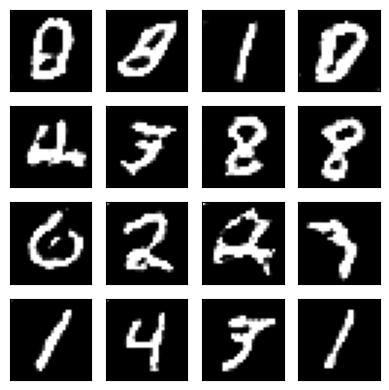

Epoch: 91/100 Discriminator Loss: 1.6663 Generator Loss: 0.8558
Epoch: 92/100 Discriminator Loss: 2.9240 Generator Loss: 4.4602
Epoch: 93/100 Discriminator Loss: 4.1261 Generator Loss: 2.3919
Epoch: 94/100 Discriminator Loss: 5.1806 Generator Loss: 6.5668
Epoch: 95/100 Discriminator Loss: 1.4689 Generator Loss: 1.4555
Epoch: 96/100 Discriminator Loss: 1.3126 Generator Loss: 1.2603
Epoch: 97/100 Discriminator Loss: 1.9533 Generator Loss: 0.8863
Epoch: 98/100 Discriminator Loss: 1.8874 Generator Loss: 1.2753
Epoch: 99/100 Discriminator Loss: 1.5837 Generator Loss: 2.9261
Epoch:100/100 Discriminator Loss: 1.3197 Generator Loss: 2.3379


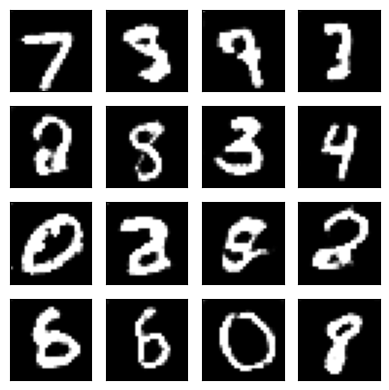

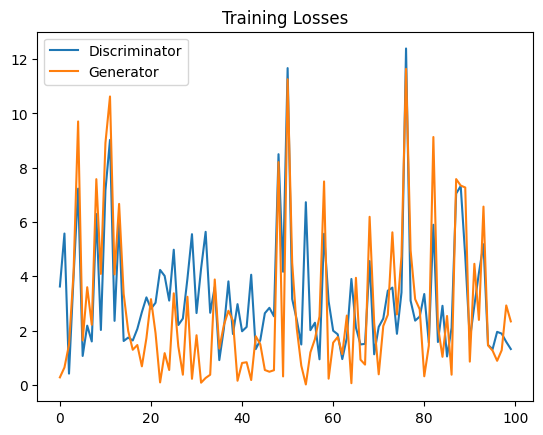

In [ ]:
train(g_learning_rate=0.0001, g_beta_1=0.9, d_learning_rate=0.001, d_beta_1=0.9, leaky_alpha=0.2);

Utilicé LeakyReLU=0.2 para el experimento anterior. Las pérdidas oscilan más, pero las imágenes generadas lucen igual de bien.

## References

https://github.com/naokishibuya/deep-learning

<a id="ref1"></a>
### [1] MNIST dataset

Yann LeCun

http://yann.lecun.com/exdb/mnist/

<a id="ref2"></a>
### [2] Deep Convolutional GANs

Udacity

https://github.com/udacity/deep-learning/blob/master/dcgan-svhn/DCGAN.ipynb

<a id="ref3"></a>
### [3] Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks

Alec Radford & Luke Metz (indico Research), Soumith Chintala (Facebook AI Research)

https://arxiv.org/pdf/1511.06434.pdf